# Libraries

In [47]:
# Standard
import numpy as np
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data Science
from scipy import stats
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from scipy.stats import shapiro
import statsmodels.api as sm
from scipy.stats import levene
from scipy.stats import f_oneway
from scipy.stats import kruskal
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from scipy.stats import studentized_range
from statsmodels.stats.oneway import effectsize_oneway
from statsmodels.stats.oneway import convert_effectsize_fsqu

# Other
from IPython.display import display, Markdown

# Dataset

In [2]:
df = sns.load_dataset("penguins")

# Data Cleaning

In [3]:
def data_structure(df):
    display(Markdown("## Dataset head"))
    display(df.head())
    display(Markdown("## Shape"))
    print(df.shape)
    display(Markdown("## Info"))
    print(df.info())
    display(Markdown("## Describe"))
    display(df.describe())
    display(Markdown("## Unique values"))
    print(df.nunique())
    display(Markdown("## Null"))
    print(df.isnull().sum())
    display(df[df.isna().any(axis=1)])
    display(Markdown("## Duplicates"))
    print(df.duplicated().sum())
    display(df[df.duplicated()])

In [4]:
data_structure(df)

## Dataset head

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


## Shape

(344, 7)


## Info

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB
None


... (6 outputs left out)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN
246,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN
286,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN
324,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN
336,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN


## Duplicates

0


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex


In [5]:
def plot_boxplots_grid(df, color="skyblue", ncols=2):

    numeric_cols = df.select_dtypes(include="number").columns

    if len(numeric_cols) == 0:
        print("No numeric variables")
        return

    n = len(numeric_cols)
    nrows = (n + ncols - 1) // ncols

    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(6 * ncols, 4 * nrows)
    )

    axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

    for i, col in enumerate(numeric_cols):

        sns.boxplot(
            x=df[col],
            color=color,
            ax=axes[i]
        )

        axes[i].set_title(f"Boxplot - {col}")
        axes[i].set_xlabel(col)

    # Removes unused axes
    for j in range(n, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()


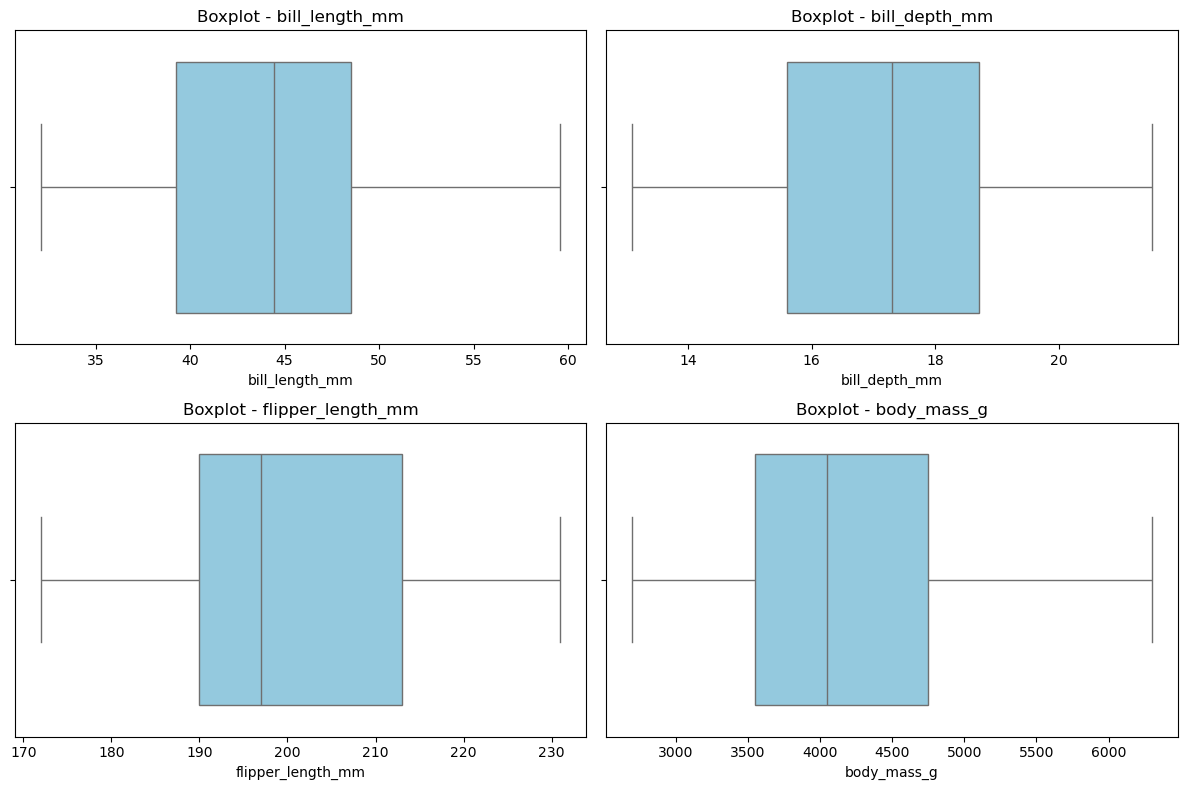

In [6]:
plot_boxplots_grid(df)

I have to remove the data for penguins with no other info than species and island. Whenever I will include sex in the analysis, I will remove also the data with no sex 

In [7]:
print("Shape before cleaning", df.shape)
df = df[~df["bill_length_mm"].isna()]
print("Shape after cleaning", df.shape)

Shape before cleaning (344, 7)
Shape after cleaning (342, 7)


In [8]:
print("Shape before cleaning", df.shape)
df_sex = df[~df["sex"].isna()]
print("Shape after cleaning (new dataset)", df_sex.shape)

Shape before cleaning (342, 7)
Shape after cleaning (new dataset) (333, 7)


# Descriptive statistics

,count,mean,std,min,25%,50%,75%,max
species,,,,,,,,
Adelie,151.0,3700.662252,458.566126,2850.0,3350.0,3700.0,4000.0,4775.0
Chinstrap,68.0,3733.088235,384.335081,2700.0,3487.5,3700.0,3950.0,4800.0
Gentoo,123.0,5076.016260,504.116237,3950.0,4700.0,5000.0,5500.0,6300.0


<Axes: ylabel='body_mass_g'>

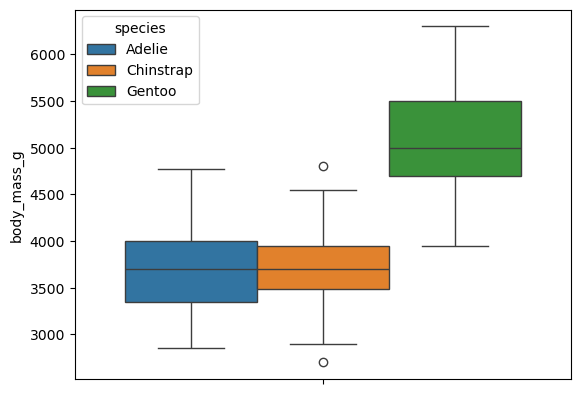

In [17]:
display(df.groupby("species")["body_mass_g"].describe())
sns.boxplot(y='body_mass_g', hue='species', data=df)

count         mean         std     min      25%     50%  \
species   sex                                                               
Adelie    Female   73.0  3368.835616  269.380102  2850.0  3175.00  3400.0   
          Male     73.0  4043.493151  346.811553  3325.0  3800.00  4000.0   
Chinstrap Female   34.0  3527.205882  285.333912  2700.0  3362.50  3550.0   
          Male     34.0  3938.970588  362.137550  3250.0  3731.25  3950.0   
Gentoo    Female   58.0  4679.741379  281.578294  3950.0  4462.50  4700.0   
          Male     61.0  5484.836066  313.158596  4750.0  5300.00  5500.0   

                      75%     max  
species   sex                      
Adelie    Female  3550.00  3900.0  
          Male    4300.00  4775.0  
Chinstrap Female  3693.75  4150.0  
          Male    4100.00  4800.0  
Gentoo    Female  4875.00  5200.0  
          Male    5700.00  6300.0

<Axes: xlabel='species', ylabel='body_mass_g'>

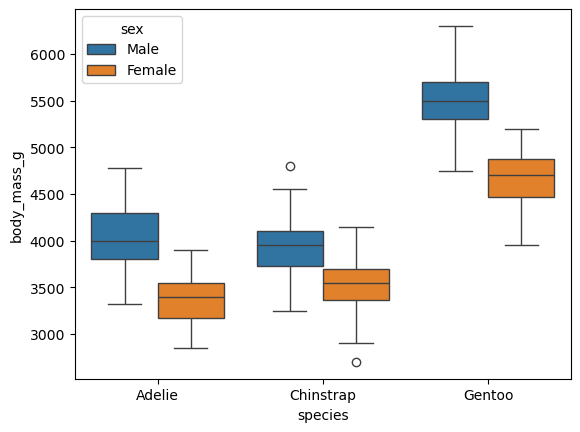

In [19]:
display(df_sex.groupby(["species", "sex"])["body_mass_g"].describe())
sns.boxplot(x='species', y='body_mass_g', hue='sex', data=df_sex)

# One-way ANOVA

## Introduction

Better than multiple t-tests, because it decreases the chance of committing Type I error (false positive)

Question: *does average body weight differ between species?*

$H_0 : \mu_{Adelie} = \mu_{Chinstrap} = \mu_{Gentoo}$

$H_1$ : at least one differs

* Model = Ordinary Least Squares, the weight of a penguin is a linear combination
    * $Y_{ij} = \mu + \alpha_i + \epsilon_{ij}$ where 
        * $Y_{ij}$ is the weight of a single penguin, 
        * $\mu$ the overall average, 
        * $\alpha_i$ the effect of species i, 
        * $\epsilon_{ij}$ a casual error
* $F = \frac{MS_{between-groups}}{MS{within-group}}$, so the ratio between the average variability between and within groups
    * $MS$ = Mean Squares, calculated as
        * $MS = \frac{SS}{df}$ where SS = Sum of Squares and df = degrees of freedom
    * $MS_{between-groups}$ is the difference between averages and the overall average
    * $MS_{within-groups}$ is the difference between the observations inside a group and the average of that group
* Type of ANOVA
    * Type I = sequential Sum of Squares, depending on the order
    * Type II = each factor is evaluated accounting other principal effects, without interactions
    * Type III = interactions are included

## ANOVA

In [21]:
df_anova = df[["species", "body_mass_g"]]

In [ ]:
model = ols(
    "body_mass_g ~ C(species)",
    data=df_anova
).fit()

anova_results = anova_lm(model, typ=2)

print(anova_results)

                  sum_sq     df           F        PR(>F)
C(species)  1.468642e+08    2.0  343.626275  2.892368e-82
Residual    7.244348e+07  339.0         NaN           NaN


Rows:
* C(species) = variability between species
* Residual = variability within species

Columns:
* Sum of squares of residuals explained by variability within species, and residual (unexplained by the model, within groups)
* Degrees of freedom (k-1 for groups, N-k for residuals)
* F = explained above
* PR(>F) = p-value

> Results

*p-value* ~ 0, the Null hypothesis must be rejected = There is statistical evidence that at least one average differs

## Verification of assumptions (Shapiro-Wilk)

Question: *Are residuals of the model (difference between estimated and observed weight) normally distributed?*

$H_0$ : Residuals follow a normal distribution

$H_1$ : Residuals don't follow a normal distribution

Shapiro-Wilk statistic varies between 0 and 1 (normality).\
In the Q-Q plot:
* points close to the diagonal = normality
* deviations at the low- and high-end = issues with tails
* curve = asymmetry or other issues

In [24]:
residuals = model.resid

stat, p_value = shapiro(residuals)

print("Shapiro-Wilk statistic:", stat)
print("P-value:", p_value)

Shapiro-Wilk statistic: 0.9916575409473666
P-value: 0.051183269139589135


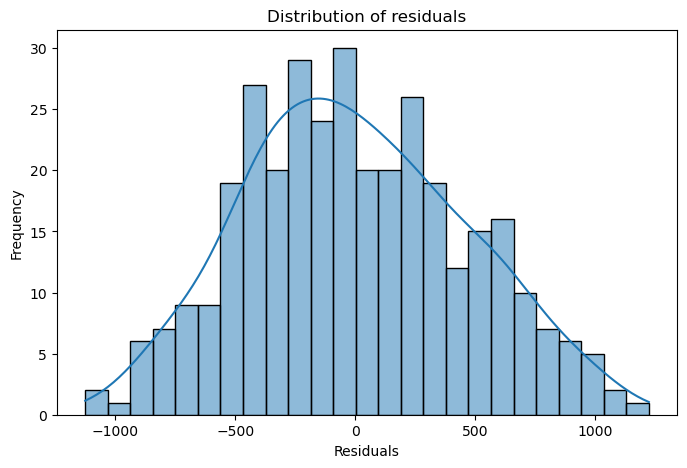

In [25]:
plt.figure(figsize=(8, 5))

sns.histplot(
    residuals,
    kde=True,
    bins=25
)

plt.title("Distribution of residuals")
plt.xlabel("Residuals")
plt.ylabel("Frequency")

plt.show()

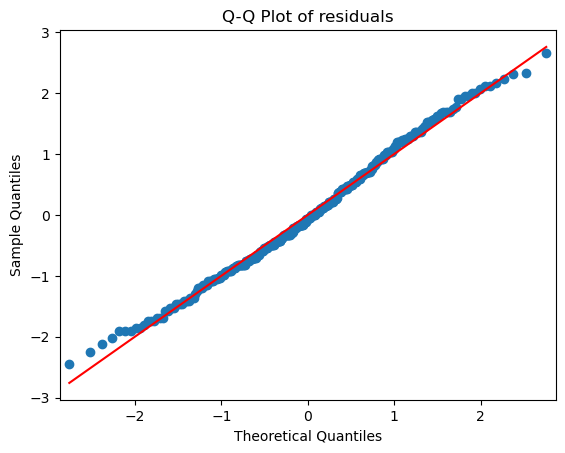

In [27]:
sm.qqplot(
    residuals,
    line="s",
    fit=True
)

plt.title("Q-Q Plot of residuals")
plt.show()

We cannot conclude that the residuals are not normal, even if the p-value is slightly than the threshold $\alpha = 0.05$.\
Slight deviations from normality are detected from the plots (asymmetry in the distribution of residuals and deviations from the diagonal in the Q-Q plot)

## Verification of assumptions (Levene)

homoscedasticity

Question: *Are variances homoscedastic (is the variability within groups comparable)?*

$H_0 : \sigma^2_{Adelie} = \sigma^2_{Chinstrap} = \sigma^2_{Gentoo}$

$H_1$ : at least one differs

The test does not compare the variances. Instead it transforms the data in distances from the group center.\
$Z_{ij} = |Y_{ij} - Center_i|$ where:
* $Z_{ij}$ is the absolute distance from the center of the group i of penguin j 
* $Y_{ij}$ is the weight of the penguin j of species i
* $Center_i$ is the center of the species i. Center = median is the robust version of the test (can tolerate extreme values and non-normal distributions)

Then an ANOVA is performed on those distances.\
Levene's statistic is the F of the ANOVA 

In [29]:
adelie = df_anova[df_anova["species"] == "Adelie"]["body_mass_g"]
chinstrap = df_anova[df_anova["species"] == "Chinstrap"]["body_mass_g"]
gentoo = df_anova[df_anova["species"] == "Gentoo"]["body_mass_g"]

stat, p_value = levene(
    adelie,
    chinstrap,
    gentoo,
    center="median"
)

print("Levene statistic:", stat)
print("P-value:", p_value)

Levene statistic: 5.12025099751946
P-value: 0.006445082805324017


There is statistical evidence to conclude that at least one variance differs.\
This means that one of the assumptions of the ANOVA is false 

# Welch ANOVA

Since the variances within groups are not comparable (Levene's test), the Welch ANOVA does not assume comparable variances.\
In conventional ANOVA the internal variance is estimated, while Welch ANOVA considers separately variance and numerosity of each group. This way, groups with higher uncertainty contribute differently to the comparison of averages 

The hypotheses are the same as a conventional ANOVA

In [40]:
welch_result = f_oneway(
    adelie,
    chinstrap,
    gentoo,
    equal_var=False
)

print("F Welch statistic =", welch_result.statistic)
print("p-value =", welch_result.pvalue)

F Welch statistic = 317.5722671041561
p-value = 3.093700645799682e-61


This means that, as for conventional One-Way ANOVA, the Null Hypothesis must be rejected and at least one group differs

# Kruskal-Wallis

A non-parametric test used to compare 3 or more independent groups. It does not compare averages but ranks. It does not require normality, since it decreases the dependency on the shape of the data

$H_0$ : distributions are comparable

$H_1$ : at least one differs

In [41]:
kruskal_result = kruskal(
    adelie,
    chinstrap,
    gentoo
)

print("H Kruskal-Wallis statistic =", kruskal_result.statistic)
print("p-value =", kruskal_result.pvalue)

H Kruskal-Wallis statistic = 217.59924143680436
p-value = 5.609512095829062e-48


The Null Hypothesis must be rejected and at least one group has different distribution.\
H statistic measures how much the average rank in each group differs from the ones expected for comparable distributions

# Post-hoc comparison

## Introduction

After the Welch ANOVA, we know that at least one average differs, but we still don't know which one(s). In this case there are 3 comparisons:
* Adelie vs Chinstrap
* Adelie vs Gentoo
* Chinstrap vs Gentoo

We could perform 3 separate *t-tests*, but every test has a 5% chance of committing Type I error (false positive)

``` python
from scipy.stats import ttest_ind

ttest_ind(adelie, chinstrap)
ttest_ind(adelie, gentoo)
ttest_ind(chinstrap, gentoo)
```

The overall chance of Type I error would increase due to the Family-Wise Error Rate (FWER).\
$FWER = 1 - (1- \alpha)^n = 0.143$ that would mean a 14.3% chance of errors in our case.\
Post-hoc tests use specific corrections to control the FWER

## Tukey HSD

HSD = *Honestly Significant Difference*\
After an ANOVA, this tests allow to establish which couple of groups are statistically different.\
2 averages at a time are compared to a threshold (HSD) that depends on:
* variability of residuals
* N (observations)
* k (groups)
* significance

Since Levene's test evidenced inhomogeneous variances, the correct test for Welch ANOVA is Games-Howell. \
However, the conventional Tukey HSD will be performed as an example

In [42]:
tukey = pairwise_tukeyhsd(
    endog=df_anova["body_mass_g"],
    groups=df_anova["species"],
    alpha=0.05
)

print(tukey)

     Multiple Comparison of Means - Tukey HSD, FWER=0.05      
  group1    group2  meandiff p-adj    lower     upper   reject
--------------------------------------------------------------
   Adelie Chinstrap   32.426 0.8807 -126.5002  191.3522  False
   Adelie    Gentoo 1375.354    0.0 1243.1786 1507.5294   True
Chinstrap    Gentoo 1342.928    0.0  1178.481  1507.375   True
--------------------------------------------------------------


Tukey assumes homogeneity between variances. \
As a consequence, p-value and confidence intervals obtained from this test could not be reliable.\
The column reject indicates if $H_0$ must be rejected. \
As a consequence, if this test was reliable, there woul not be a statistically significant difference between the means of Adelie and Chinstrap, while Gentoo would have been the different one in the trio

## Games-Howell

This test does not assume equal variances

In [44]:
def games_howell(data, dv, between, alpha=0.05):

    groups = data.groupby(between)[dv]

    results = []

    names = list(groups.groups.keys())

    for i in range(len(names)):
        for j in range(i + 1, len(names)):

            g1 = groups.get_group(names[i])
            g2 = groups.get_group(names[j])

            n1, n2 = len(g1), len(g2)
            mean1, mean2 = g1.mean(), g2.mean()
            var1, var2 = g1.var(), g2.var()

            diff = mean1 - mean2

            se = np.sqrt(
                var1 / n1 + var2 / n2
            )

            t = abs(diff) / se

            df = (var1/n1 + var2/n2)**2 / (
                (var1/n1)**2 / (n1-1) +
                (var2/n2)**2 / (n2-1)
            )

            q = t * np.sqrt(2)

            p_value = studentized_range.sf(
                q, len(names), df
            )

            critical = studentized_range.ppf(
                1-alpha, len(names), df
            )

            margin = critical * se / np.sqrt(2)

            results.append({
                "group1": names[i],
                "group2": names[j],
                "mean_diff": diff,
                "se": se,
                "df": df,
                "p_value": p_value,
                "lower": diff - margin,
                "upper": diff + margin,
                "reject": p_value < alpha
            })

    return pd.DataFrame(results)

In [45]:
gh_results = games_howell(
    data=df_anova,
    dv="body_mass_g",
    between="species"
)

print(gh_results.round(4))

      group1     group2  mean_diff       se        df  p_value      lower  \
0     Adelie  Chinstrap    -32.426  59.7064  152.4548   0.8502  -173.7408   
1     Adelie     Gentoo  -1375.354  58.8109  249.6426   0.0000 -1514.0172   
2  Chinstrap     Gentoo  -1342.928  65.1028  170.4044   0.0000 -1496.8555   

       upper  reject  
0   108.8889   False  
1 -1236.6908    True  
2 -1189.0006    True  


So, since the variances are inhomogeneous, the Games-Howell test shows that Adelie and Chinstrap have similar averages, while Gentoo has a different average

# Effect size

Until now, the question was: *are the differences between the averages of different species statistically significant?*.\
The effect-size instead answers the question: *How much of the variance is explained by differences between species?*

* $\eta^2 = \frac{SS_{between}}{SS{total}}$, so the ratio between the variability between groups and the total variability
    * $SS$ = Sum of Squares

How to interpret the results:\
A convention is Cohen'interpretation (1988)
* $\eta^2 = 0.01$ -> small effect
* $\eta^2 = 0.06$ -> intermediate effect
* $\eta^2 = 0.14$ -> big effect

## Classic

This effect-size cannot be employed because of the differences between variances

In [46]:
eta_squared = (
    anova_results.loc["C(species)", "sum_sq"]
    / anova_results["sum_sq"].sum()
)

print("Eta-squared:", eta_squared)

Eta-squared: 0.6696719536879615


## Welch Effect Size

This is the Welch-based eta-squared and considers the different variances and numerosities of groups

In [49]:
groups = [adelie, chinstrap, gentoo]

means = np.array([g.mean() for g in groups])
variances = np.array([g.var(ddof=1) for g in groups])
nobs = np.array([g.count() for g in groups])

f2 = effectsize_oneway(
    means,
    variances,
    nobs,
    use_var="unequal"
)

eta2_welch = convert_effectsize_fsqu(f2=f2).eta2

print(f"Welch effect size (eta-squared) = {eta2_welch:.4f}")

Welch effect size (eta-squared) = 0.6508


This cannot be directly interpreted as the total variance explained, since that would be the approach of the classic eta-squared.\
Cohen's tresholds cannot be directly transferred to this value. However, an indication could be:
* $\eta^2 < 0.06$ -> small effect
* $\eta^2 = 0.14$ -> intermediate effect
* $\eta^2 = 0.30$ -> high effect
* $\eta^2 > 0.50$ -> very high effect

As a consequence, the effect size can be classified as *very high*